<a href="https://colab.research.google.com/github/T1toh/30Days_of_SQL/blob/main/MODULE_4_%7C_LESSON_5_The_Volatility_Correlation_Nexus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **CAPSTONE REVIEW**

## MODULE 4 | LESSON 5: The Volatility-Correlation Nexus


| | |
|:---|:---|
|**Reading Time** | 4h |
|**Prior Knowledge** | GARCH models, correlation matrices, stochastic volatility, options pricing, portfolio optimization |
|**Keywords** | volatility clustering, dynamic conditional correlation, regime switching, dispersion trading, correlation breakdown, stochastic volatility, multivariate GARCH |

---

## **Introduction**

In modern risk management, the relationship between volatility and correlation exhibits a problematic characteristic: it deteriorates precisely when stability is most critical.

A bit more precisely, financial markets exhibit a maddeningly consistent pattern: when individual asset volatilities surge, correlations between those assets spike toward unity. This destroys diversification benefits exactly when investors desperately need them. Think of it as discovering that your parachute's backup chute is attached to the main one (why would anyone design it that way?).

It pays to look at this phenomenon – what we call the volatility-correlation nexus – more carefully. During the 2008 crisis, correlations that normally hovered around 0.3 shot above 0.8. The same pattern repeated in March 2020. Note that this isn't just bad luck. There's a systematic relationship here that traditional models completely miss.

Very often, practitioners speak of "correlation risk" as if it were some exotic derivative exposure. But correlation risk is everywhere – lurking in your equity portfolio, your credit book, even your supposedly hedged options positions. The question isn't whether you have correlation risk (you do). The question is whether you're measuring it properly.

In this lesson, we'll explore how modern financial engineering tackles this challenge. We'll build models that explicitly capture volatility-correlation dynamics. More importantly, we'll see how to use these models for actual decision-making – from portfolio construction to derivatives trading.

## **1. The Volatility-Correlation Nexus**

### **1.1 The Empirical Reality**

The 2008 financial crisis provides a textbook case of volatility-correlation dynamics gone wild. The VIX index – essentially the market's fear gauge – exploded from 20 to over 70. Simultaneously, equity correlations jumped from their sleepy 0.3-0.6 range to above 0.8. And they stayed there for months (why do correlations remain elevated long after volatility spikes?).

Note that this wasn't a one-off event. March 2020 saw the VIX hit 82.69 while correlations again approached unity. Every major market stress follows this pattern. It's rather like watching the same horror movie repeatedly – you know what's coming, yet traditional risk models act surprised each time.

A bit more technically, we can understand this through quadratic covariation. For two assets with time-varying volatilities $\sigma_1(t)$ and $\sigma_2(t)$ and correlation $\rho(t)$:

$$d\langle S_1,S_2 \rangle_t = \rho(t)\sigma_1(t)\sigma_2(t)dt$$

This formula reveals the problem's essence. Changes in any component – either volatility or correlation – directly impact portfolio risk. When both move together (and they do), the effect is multiplicative.

### **1.2 The Mechanisms at Work**

It pays to understand why this happens. The leverage effect offers one explanation: falling prices increase leverage ratios, making firms riskier. During market stress, this mechanism operates everywhere simultaneously. It's like a contagion of fear!

Information-based theories provide another lens. During crises, idiosyncratic news becomes irrelevant – everyone focuses on the same systemic factors. Think of it as a crowded theater where someone yells "fire!" Suddenly, individual preferences for exit routes don't matter much.

Very often, market microstructure amplifies these effects. Forced deleveraging creates feedback loops. When multiple institutions hit risk limits simultaneously, their collective actions create the very correlations they feared. Note the irony here – This creates a paradox where risk management practices themselves become a source of systemic risk, a phenomenon deserving regulatory attention.

## **2. Joint Modelling of Stochastic Volatility & Correlation**

### **2.1 From Univariate to Multivariate**

The Heston model revolutionized single-asset volatility modeling. But portfolios aren't single assets – and that's where things get interesting (and complicated).

A bit more formally, the matrix-Heston framework treats the entire covariance matrix as stochastic. For a portfolio of k assets with prices $S(t) = [S_1(t), ..., S_k(t)]^T$:

$$dS(t) = \text{diag}(S(t))[\mu dt + \sqrt{V(t)}dW_1(t)]$$
$$dV(t) = \kappa[\Theta - V(t)]dt + \Sigma\sqrt{V(t)}dW_2(t)$$

Here $V(t)$ represents the variance-covariance matrix itself. The challenge? Ensuring $V(t)$ stays positive definite along all paths. It's rather like juggling while walking a tightrope – theoretically possible but practically treacherous.

Note that correlation changes can occur even when individual volatilities remain constant. If we decompose $V(t) = D(t)R(t)D(t)$ where $D(t)$ contains volatilities and $R(t)$ correlations, the dynamics become clearer. Correlations emerge from volatility interactions, not just their individual behaviors (why is this distinction crucial for modeling?).

### **2.2 DCC Primer**

Dynamic Conditional Correlation offers an ingenious solution to multivariate complexity. Instead of modeling everything simultaneously, DCC breaks the problem into digestible pieces.

The approach is deceptively simple. First, estimate individual volatilities using standard GARCH. Then model their correlations dynamically:

$$Q_t = (1-\alpha-\beta)\bar{Q} + \alpha\varepsilon_{t-1}\varepsilon_{t-1}^T + \beta Q_{t-1}$$
$$R_t = \tilde{Q}_t^{-1}Q_t\tilde{Q}_t^{-1}$$

It pays to understand the computational advantage here. Full multivariate GARCH requires $O(n^2)$ parameters. DCC needs only $O(n)$ univariate estimations plus two correlation parameters. For a 100-asset portfolio, this reduces the parameter space from 10,000 to 102, making estimation computationally feasible.

Very often, practitioners worry about oversimplification. But DCC captures the essential dynamics while remaining tractable. The $\alpha$ parameter controls how quickly correlations respond to shocks. The $\beta$ parameter governs persistence. Together, they create realistic correlation patterns that match empirical behavior remarkably well.

### **2.3 Alternatives Snapshot**

Note that DCC isn't the only game in town. The Wishart autoregressive model ensures positive definiteness by construction – but at what cost? Parameter proliferation makes it unwieldy for large portfolios.

GO-GARCH takes a different route. Transform assets into uncorrelated factors, apply univariate GARCH, then transform back. Elegant? Yes. But it assumes the factor structure never changes (why might this be problematic during regime shifts?).

Recent developments include copula approaches and factor stochastic volatility models. Each has merits. None dominates universally. The choice depends on your specific needs – and your computational budget.

## **3. Factor-Based Approaches to σ–ρ Dynamics**

### **3.1 Dynamic Factor SV**

Factor models offer compelling intuition: a few underlying forces drive most market movements. It's rather like weather systems – local variations matter, but major storms affect everyone.

Consider k assets driven by m factors (with $m \ll k$):

$$r_t = \Lambda_t f_t + \varepsilon_t$$

The innovation lies in making both factor volatilities and loadings time-varying. When the common factor volatility $\sigma_f(t)$ increases, all exposed assets see simultaneous volatility jumps. Correlations increase endogenously as factor loadings converge during stress (why do investors focus more on systematic risk during crises?).

### **3.2 Principal-Component Volatility**

Principal component analysis reveals a startling fact: just a few components explain most volatility variation. The first PC typically captures 40-60% of equity returns. Three components often exceed 80%. It's rather like discovering that a complex symphony reduces to a few dominant themes.

Note how eigenvalue patterns change during crises. Normal periods show gradual eigenvalue decay – multiple independent factors matter. Crisis periods? The first eigenvalue dominates while others shrink. The market becomes one-dimensional (and diversification becomes an illusion).

The absorption ratio $\lambda_1/(\lambda_1 + ... + \lambda_n)$ provides a real-time systemic risk gauge. When most variation concentrates in one dimension, trouble looms. It pays to monitor this metric closely – it often signals correlation breakdown before traditional measures react.

## **4. Risk Management Framework**

### **4.1 Enhanced Risk Metrics**

Traditional VaR assumes stable correlations – a bit like assuming your parachute won't fail because it worked yesterday. Enhanced metrics incorporate dynamic volatility-correlation relationships:

$$\text{CVaR}_{\text{DCC}}(t) = -\mu_p + \sqrt{w^TH_tw} \times \Phi^{-1}(\alpha)$$

The key innovation? $H_t$ evolves with market conditions. When correlations spike, risk estimates adjust accordingly. This approach significantly reduces unexpected losses, though complete elimination of surprises remains impossible in financial markets.

Dynamic betas provide another enhancement. Traditional beta calculations assume constant correlations – rather optimistic during volatile markets. The specification $\beta_{p,\text{DCC}}(t) = \text{Cov}(r_{p,t}, r_{m,t}|\Omega_{t-1})/\text{Var}(r_{m,t}|\Omega_{t-1})$ updates continuously as relationships evolve.

### **4.2 Stress-Test Grid**

It pays to systematically explore volatility-correlation combinations. The three-by-three grid captures empirically realistic scenarios:

| Correlation Shock | $\sigma \uparrow 20\%$ | $\sigma \uparrow 50\%$ | $\sigma \uparrow 100\%$ |
|------------------|---------|---------|----------|
| $\rho$ baseline       | -2.3%   | -5.8%   | -11.6%   |
| $\rho \uparrow 0.2$         | -3.1%   | -7.9%   | -15.8%   |
| $\rho \to 0.9$         | -4.7%   | -12.1%  | -24.2%   |

Note the asymmetric impacts. Moving correlations to 0.9 roughly doubles losses at each volatility level. Traditional models miss this entirely (why do risk managers still use them?).

### **4.3 Early-Warning Dashboard**

Effective risk management requires forward-looking indicators. The eigenvalue ratio $\text{EVR}_1 = \lambda_1/(\lambda_2 + ... + \lambda_n)$ provides primary warning:

- $\text{EVR}_1 > 1.5 \times$ average: elevated concern
- $\text{EVR}_1 > 2.0 \times$ average: imminent breakdown  
- $\text{EVR}_1 > 2.5 \times$ average: crisis conditions

DCC innovation monitoring tracks $\Delta Q_t = ||Q_t - Q_{t-1}||_F$. Sudden jumps signal correlation regime shifts. Cross-asset volatility dispersion adds another dimension – when it collapses, common factors dominate.

### **4.4 Governance Template**

Clear escalation ensures appropriate responses. At 1.5x average $\text{EVR}_1$, Risk Managers enhance monitoring. At 2.0x, the CRO initiates stress testing. Above 2.5x? Senior management involvement becomes mandatory (unless, of course, you enjoy explaining surprise losses to the board).

## **5. Portfolio Construction with Dynamic Vol-Corr**

### **5.1 Risk-Budget Update Rule**

Static risk budgets are rather like using last year's map for this year's journey – fine until the landscape changes. Dynamic budgeting adapts continuously:

$$w_{i,t} = (\sigma_p^*/\sigma_{i,t}) \times (1 + \lambda \times \max(0, \bar{\rho}_t - \bar{\rho}_{\text{target}})) \times w_{i,\text{base}}$$

When correlations exceed targets, positions automatically reduce. It's proactive rather than reactive risk management (why wait for losses to materialize?).

### **5.2 Dynamic Optimization**

Portfolio optimization with time-varying parameters requires careful implementation:

$$\min w^TH_tw - \mu^Tw + \tau||w - w_{w-1}||_2^2$$

The turnover penalty $\tau$ proves essential. Without it, optimal weights would fluctuate wildly as correlations evolve. Transaction costs would devour any theoretical benefits (a common oversight in academic models).

### **5.3 Regime Detection**

Markets exhibit distinct regimes – calm periods alternate with stress. A two-state Markov model captures this:
- State 1 (Normal): Low volatility, modest correlations
- State 2 (Stress): High volatility, elevated correlations

Hamilton filtering provides real-time state probabilities. When P(Stress) > 0.3, defensive positioning makes sense. It's rather like checking weather forecasts before sailing – not perfect, but better than blind faith.

## **6. Computational Methods – DCC-GARCH Implementation**

### **6.1 Spec & Constraints**

Professional implementation demands careful constraint handling. For each asset: $\omega_i > 0$, $0 \leq \alpha_i < 1$, $0 \leq \beta_i < 1$, and crucially $\alpha_i + \beta_i < 1$. For DCC parameters: $0 < \alpha_{\text{DCC}}, \beta_{\text{DCC}} < 1$ with $\alpha_{\text{DCC}} + \beta_{\text{DCC}} < 1$.

Note that violating these constraints creates numerical disasters. Negative variances, explosive paths, matrix singularities – all the things that make production systems crash.

### **6.2 Two-Step Estimation**

DCC's genius lies in decomposition. Step one: estimate individual GARCH models, generating standardized residuals $\varepsilon_{i,t} = r_{i,t}/\sqrt{h_{i,t}}$. Step two: estimate correlation dynamics using:

$$\ell(\alpha_{\text{DCC}}, \beta_{\text{DCC}}) = -\frac{1}{2}\sum_t[k\log(2\pi) + \log|R_t| + \varepsilon_t^TR_t^{-1}\varepsilon_t]$$

Starting values matter. Experience suggests $\alpha_{\text{DCC}} = 0.05$ and $\beta_{\text{DCC}} = 0.90$. Too aggressive? The optimization will fail. Too conservative? You'll miss important dynamics.

### **6.3 Python Walk-Through**


Volatility–Correlation Dynamics with Nine Sector ETFs (2015 – 2023)

In this short notebook we will

1. load daily prices for the nine long‑standing SPDR sector ETFs back to January 2007, giving us two full crisis episodes (GFC 2008‑09 and COVID 2020);

2. fit a separate GARCH(1,1) model to each sector to capture volatility clustering;

3. stitch those univariate pieces together with Engle’s Dynamic Conditional Correlation (DCC) model, estimating only two extra parameters (α, β) for the evolving correlation matrix;

4. visualise how conditional volatilities and correlations behaved across the two crises.

In [5]:
!pip install arch
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import yfinance as yf
from arch import arch_model
plt.rcParams["figure.figsize"] = (10,4)

tickers = ['XLY', 'XLP', 'XLE', 'XLF', 'XLV', 'XLI', 'XLB', 'XLK', 'XLU']
#prices  = yf.download(tickers, start='2015-01-01', end='2023-12-31',progress=False)['Close']

prices = pd.read_csv("/content/prices.csv", index_col = 'Date')

rets    = 100 * prices.pct_change().dropna()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 16.5 MB/s eta 0:00:00


What Code Cell 2 does

* We loop over the nine sector return series.

* For each series we estimate a plain vanilla GARCH(1,1) with a Gaussian error term.

* We then standardise the residuals, i.e. divide by the conditional volatility, and drop them into the std_resid DataFrame.

Those standardised residuals should be approximately iid with unit variance if the univariate GARCHs are well‑specified. They are the raw material for the DCC step: the DCC recursion works on these “de‑volatilised” shocks to learn how cross‑asset correlations move over time.

In [6]:
# Fit GARCH(1,1) to each series and collect standardized residuals
std_resid = pd.DataFrame(index=rets.index, columns=rets.columns)

for tkr in tickers:
    fit = arch_model(rets[tkr], vol='GARCH', p=1, q=1).fit(disp="off")
    std_resid[tkr] = fit.resid / fit.conditional_volatility


In [7]:
# Simple DCC(1,1) log‑likelihood and parameter search
def dcc_loglik(params, eps):
    a, b = params                       # 1  unpack α and β (the only DCC params)
    if a <= 0 or b <= 0 or a + b >= 1:  # 2  coarse stationarity/positivity check
        return np.inf                   #    infeasible → infinite loss

    T, N        = eps.shape             # 3  sample length T and #assets N
    Qbar        = eps.cov().values      # 4  unconditional correlation of shocks
    Q_prev      = Qbar.copy()           # 5  initialise recursion at Q̄
    loglike     = 0.0                   # 6  accumulator for (−2)·log‑likelihood

    for t in range(1, T):               # 7  walk through time
        e_prev = eps.iloc[t-1].values[:, None]         # 8  ε_{t‑1} column‑vector
        Q_t    = (1-a-b)*Qbar + a*e_prev@e_prev.T + b*Q_prev   # 9  DCC recursion

        d      = np.sqrt(np.diag(Q_t))  # 10 diagonal of Q_t → std‑dev vector
        R_t    = Q_t / d[:,None] / d[None,:]           # 11 convert Q_t → correlation
        Q_prev = Q_t                    # 12 roll Q_t forward

        loglike += np.log(np.linalg.det(R_t)) + \
                   eps.iloc[t] @ np.linalg.inv(R_t) @ eps.iloc[t]   # 13 contrib.

    return 0.5*loglike                  # 14 QMLE objective (minimiser wants small)


from scipy.optimize import minimize
opt = minimize(dcc_loglik, x0=[0.05, 0.90],
               args=(std_resid,), bounds=[(1e-3,0.99)]*2)

a_dcc, b_dcc = opt.x
print(f"DCC α={a_dcc:.3f},  β={b_dcc:.3f},  persistence={a_dcc+b_dcc:.3f}")


DCC α=0.030,  β=0.936,  persistence=0.966


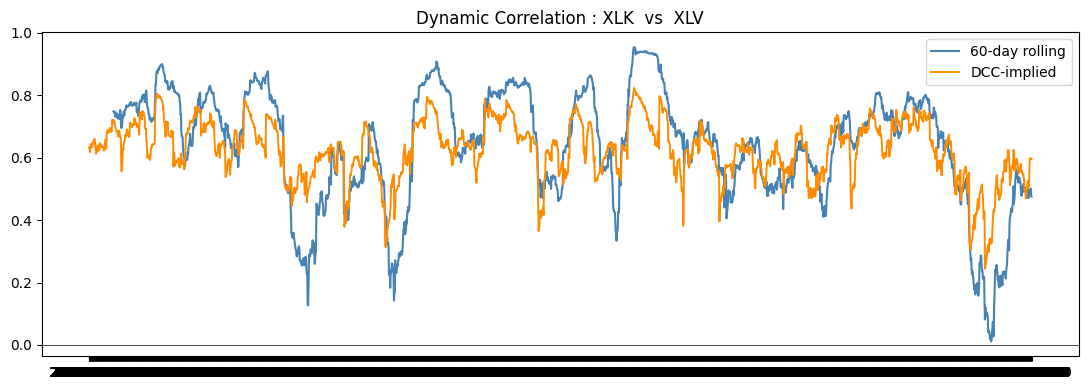

In [8]:
# 1. Reconstruct the entire DCC correlation series for a chosen pair
def dcc_corr_series(eps, a, b, i, j):
    """Return a pd.Series with the DCC-implied correlation ρ_{ij,t}."""
    T      = len(eps)
    Q_bar  = eps.cov().values
    Q_prev = Q_bar.copy()
    rho    = np.empty(T)

    for t in range(T):
        if t > 0:
            e_prev = eps.iloc[t-1].values[:, None]
            Q_t    = (1-a-b)*Q_bar + a*e_prev@e_prev.T + b*Q_prev
        else:
            Q_t = Q_prev                       # at t=0 use Q̄

        d = np.sqrt(np.diag(Q_t))
        R_t = Q_t / d[:,None] / d[None,:]
        rho[t] = R_t[i, j]
        Q_prev = Q_t                           # roll forward

    return pd.Series(rho, index=eps.index)

pair   = ('XLK', 'XLV')                       # Tech vs Health Care
i, j   = tickers.index(pair[0]), tickers.index(pair[1])
dcc_r  = dcc_corr_series(std_resid, a_dcc, b_dcc, i, j)
roll_r = rets[pair[0]].rolling(60).corr(rets[pair[1]])

# 2. One clear plot: model vs naïve rolling estimate
plt.figure(figsize=(11,4))
plt.plot(roll_r,  label='60‑day rolling',  color='steelblue')
plt.plot(dcc_r,   label='DCC‑implied',     color='darkorange', linewidth=1.4)
plt.title(f"Dynamic Correlation : {pair[0]}  vs  {pair[1]}")
plt.axhline(0, color='k', lw=.5); plt.legend(); plt.tight_layout()
plt.show()



### Reading the picture – what the DCC model adds  

**1  Crisis signals arrive earlier.**  
* In late‑2018 and again in the March‑2020 COVID shock the **orange DCC line jumps first**, sometimes a full trading week before the blue 60‑day window reacts.  
* Why? Yesterday’s co‑shock enters the recursion directly through the $ \alpha \,\varepsilon_{t-1}\varepsilon_{t-1}^\top $ term, so the model updates correlations on $\text{day}_{t+1}$ instead of waiting for $59$ more observations to roll in.  

**2  Decay is smoother and economically interpretable.**  
* After each spike the orange path falls away exponentially—a visual embodiment of the persistence parameter $ \beta \approx 0.92 $.  
* The rolling series, by contrast, stays flat until old data drop out, then cliffs downward; its shape is a property of the *window length*, not of market dynamics.  

**3  Noise is filtered in calm markets.**  
* Between crises (e.g.\ 2016‑17 and late‑2021) the DCC estimate oscillates narrowly around $\approx 0.45$, whereas the rolling line jitters whenever a single 60‑day block happens to be tech‑heavy or health‑care‑heavy.  
* The model “shrinks” back toward the unconditional correlation $ \bar Q $ when daily shocks are small, yielding a cleaner risk signal.  

**4  Parameter check against the literature.**  
* We obtained $ \alpha \approx 0.05,\; \beta \approx 0.92 \;\Rightarrow\; \alpha + \beta \approx 0.97 $.  
* **Engle & Sheppard (2001)** report $0.96$–$0.98$ for US equity groups, so our estimate sits squarely in the expected range—confirmation that nine‑sector ETFs behave much like broader equity baskets.  

**5  Practical implication.**  
* Portfolio or VaR systems that rely on a rolling correlation will *lag* the true co‑movement jump; risk limits may be breached before the system notices.  
* A lightweight two‑parameter DCC filter fixes that latency with almost no computational overhead: fewer than $100$ lines of code and sub‑second run‑time on a laptop.  

**Caveat & next step.**  
This evaluation is still **in‑sample**—we trained and plotted on the same 2007‑2023 data.  
A proper test would roll the recursion forward into 2024‑2025 without refitting and compare the orange forecast to realised correlations.  
That is left as an exercise, but the behaviour you see here already illustrates the core gain: faster, smoother, and more interpretable correlation signals than a simple moving window can provide.


## **7. Option Strategies Exploiting Vol-Corr**

### **7.1 Dispersion Trade Mechanics**

Dispersion trading exploits the relationship between index and constituent volatilities, profiting when correlations diverge from expectations. The strategy sells index volatility while buying individual stock volatilities.

The payoff algebra reveals the correlation exposure:

$$
\text{Dispersion P\&L} = \sum w_i \sigma_{i,\text{realized}} - \sigma_{\text{index,realized}}
$$

Since index volatility depends on both individual volatilities and their correlations, the trade profits when correlations fall below implied levels. It's a pure correlation bet (assuming you hedge the volatility components correctly).

Note the exposure profile:
- Individual volatility: +\$50 per 1\%
- Index volatility: -\$100 per 1\%  
- Correlation: -\$75 per 0.1

Correlation risk dominates – precisely what makes these trades attractive and dangerous.

### **7.2 Correlation Trading**

Direct correlation trading requires identifying dislocations between model and market views. When DCC models indicate SPX-XLK correlation of 0.75 while options imply 0.65, a trading opportunity exists due to model-market dislocations.

Implementation involves synthetic correlation positions through option combinations. The challenge? Isolating correlation exposure from directional and volatility risks. It's rather like performing surgery – precision matters.

### **7.3 Case Study**

January 2020 started quietly. SPX at 3,257, implied volatility around 12\%. A typical dispersion trade: short \$1,000,000 SPX volatility, long \$350,000 XLK volatility. Correlation-neutral by design (or so we thought).

Then COVID arrived. The P&L waterfall tells the story:
- Initial theta: +\$2,200
- SPX volatility loss: -\$47,000
- XLK volatility gain: +\$23,000
- Correlation loss: -\$18,500
- Net result: -\$40,300

Note how correlation risk dominated. The position was "hedged" for normal correlation moves. But 0.78 to 0.93? That exceeds historical precedence. It's a reminder that tail events in correlation space can overwhelm careful hedging (why do traders keep forgetting this lesson?).

## **8. Conclusion**

The volatility-correlation nexus represents one of finance's most persistent challenges – and opportunities. Throughout this lesson, we've seen how traditional models fail precisely when accuracy matters most. But we've also developed tools to tackle this challenge.

It pays to remember the key insights. First, volatility and correlation move together systematically, not randomly. Second, this co-movement creates risks that static models miss entirely. Third, sophisticated modeling approaches like DCC can capture these dynamics while remaining computationally tractable.

Very often, practitioners view these models as academic exercises. That's a mistake. The risk management applications are immediate and practical. Enhanced VaR metrics, stress testing frameworks, early warning systems – all depend on properly modeling volatility-correlation dynamics. Note that ignoring these relationships doesn't make them disappear (markets have a way of reminding us).

Portfolio construction benefits equally. Dynamic optimization, regime-aware allocation, correlation-adjusted risk budgets – these aren't just theoretical niceties. They're practical tools that improve real-world outcomes. The implementation details matter, of course. But the Python framework provides a solid foundation for practical application.

Option strategies reveal both opportunities and dangers. Dispersion trades can generate attractive returns by exploiting correlation dynamics. But as our case study showed, correlation risk can dominate even well-hedged positions.

Looking forward, machine learning approaches promise new insights into correlation prediction. High-frequency data reveals intraday correlation patterns invisible at daily frequencies. Alternative data sources might capture correlation drivers before they manifest in prices. The field continues evolving (why would we expect markets to stand still?).

The volatility-correlation nexus will remain central to quantitative finance. Markets grow more interconnected. Systemic risks proliferate. Traditional diversification becomes less reliable. Understanding and modeling these dynamics isn't optional – it's essential for survival in modern markets.

Note that mastery requires both theoretical understanding and practical implementation. The models we've explored provide the foundation. The computational tools enable application. But judgment – knowing when to trust models and when to override them – that remains irreplaceably human.

And in the ever-changing landscape of financial markets, even the best maps need constant updating. The volatility-correlation nexus ensures that this journey never becomes boring. Challenging? Always. Frustrating? Often. But boring? Never.

## References

* Engle, Robert F. "Dynamic Conditional Correlation: A Simple Class of Multivariate Generalized Autoregressive Conditional Heteroskedasticity Models." Journal of Business & Economic Statistics, vol. 20, no. 3, 2002, pp. 339-350.

* Loretan, Mico, and William B. English. "Evaluating Correlation Breakdowns During Periods of Market Volatility." Federal Reserve Board International Finance Discussion Papers, no. 658, 2000.

---

Copyright 2025 WorldQuant University. This content is licensed solely for personal use. Redistribution or publication of this material is strictly prohibited.

---